https://www.howtoforge.com/tutorial/how-to-use-ftp-on-the-linux-shell/

Order files here
Use ftp via ftp ftp2.archive.arm.gov
Login with User and Password
Name: franzihe
Password:

Change directory cd /hellmuthf2/232434

Download files with FTP by setting local FTP file download directory 
lcd /scratch/franzihe/input/COMBLE/mwr

mget *anxmwr*

In [1]:
# rsync -av --progress /scratch/franzihe/input/COMBLE u6030275@notchpeak.chpc.utah.edu:/uufs/chpc.utah.edu/common/home/coopers-group1/Franziska/data 

In [2]:
import os
import pathlib
import sys
import socket

hostname = socket.gethostname()
print(hostname)


abs_path = str(pathlib.Path(hostname).parent.absolute())
WORKDIR = abs_path[:- (len(abs_path.split('/')[-2] + abs_path.split('/')[-1])+1)]


if "mimi" in hostname:
    DATA_DIR = "/scratch/franzihe/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/COMBLE/"

elif "augustiner" in hostname: 
    DATA_DIR = "/home/franzihe/Data/"
    FIG_DIR = "/home/franzihe/Documents/Figures/COMBLE/"

elif "wessel" in hostname:
    DATA_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/"
    FIG_DIR = "/uio/kant/geo-metos-u1/franzihe/Documents/Figures/COMBLE/"


INPUT_DATA_DIR = os.path.join(DATA_DIR, 'input')
UTILS_DIR = os.path.join(WORKDIR, 'utils')

sys.path.append(UTILS_DIR)

# make figure directory to put in reflectivity processed data
try:
    new_dir = pathlib.Path(FIG_DIR)
    new_dir.mkdir(parents=True, exist_ok=True)
except OSError:
    pass

mimi.uio.no


## Import python packages

* `Python` environment requirements: file requirements_retrieval.txt
* load `python` packages from imports.py
* load `functions` from functions.py

In [3]:
# supress warnings
import warnings
warnings.filterwarnings('ignore') # don't output warnings

# import packages
from imports import(xr, glob, plt,radar, np, DateFormatter, datetime, cm, pd, da, fct)


In [4]:
# reload imports
%load_ext autoreload
%autoreload 2

In [5]:
site = "COMBLE"
years = ["2019","2020"]
months = ["12", "01", "02", "03", "04"]
days = np.arange(1, 32)

In [6]:
year = "2019"
month = "12"
day = "05"
date = "{}{}{}".format(year, month, day)

In [34]:
kazr_in = sorted(glob(os.path.join(INPUT_DATA_DIR, '{}/kazr*/*{}*.nc'.format(site,date))))
armbeatm_in = sorted(glob(os.path.join(INPUT_DATA_DIR, '{}/armbeatm*/*{}*.nc'.format(site, year))))
intpsonde_in = sorted(glob(os.path.join(INPUT_DATA_DIR, '{}/interpolatedsonde*/*{}*.nc'.format(site,date))))


In [36]:
ds_intpsonde = xr.open_mfdataset(intpsonde_in, decode_times=True)
ds_intpsonde.coords['time'] = fct.adjust_time(ds_intpsonde)

In [14]:
ds_armbeatm = xr.open_mfdataset(armbeatm_in, decode_times=True)
ds_armbeatm.coords['time'] = fct.adjust_time(ds_armbeatm)

In [15]:
ds_dict = {}
for hours in range(len(kazr_in)):
    ds_dict[hours] = xr.open_dataset(kazr_in[hours], decode_times=True)

    ds_dict[hours].coords['time'] = fct.adjust_time(ds_dict[hours])

# create dataset with all hours    
_ds = list(ds_dict.values())
_coord = list(ds_dict.keys())
ds_kazr = xr.concat(objs=_ds, dim='time', coords="all")

In [17]:
# Define start and end time of individual day
day_start = datetime.datetime.strptime("{} 00:00:00.00".format(date), '%Y%m%d %H:%M:%S.%f').strftime('%Y-%m-%dT%H:%M:%S.%f')
day_end = (datetime.datetime.strptime("{} 00:00:00.00".format(date), '%Y%m%d %H:%M:%S.%f') + datetime.timedelta(hours=23, minutes=59)).strftime('%Y-%m-%dT%H:%M:%S.%f')
_xmax = (datetime.datetime.strptime(day_end, '%Y-%m-%dT%H:%M:%S.%f') + datetime.timedelta(minutes=1,)).strftime('%Y-%m-%dT%H:%M:%S.%f')
  

In [61]:
# select reflectivity to make radar reflectivity plot
_Ze = ds_kazr['reflectivity'].sel(time=slice(day_start, day_end))

# select mean_doppler_velocity
_W = ds_kazr['mean_doppler_velocity'].sel(time = slice(day_start, day_end))

_pp = ds_armbeatm.precip_rate_sfc.sel(time = slice(day_start, day_end))
_air_temp = (ds_armbeatm.temperature_sfc - 273.15).sel(time = slice(day_start, day_end))
_air_temp = _air_temp.assign_attrs(ds_armbeatm.temperature_sfc.attrs).assign_attrs({'units':'degC'})
# _air_temp_h = (ds_armbeatm.temperature_h - 273.15).sel(time = slice(day_start, day_end))
# _air_temp_h = _air_temp_h.assign_attrs(ds_armbeatm.temperature_h.attrs).assign_attrs({'units':'degC'})
_u_sfc = ds_armbeatm.u_wind_sfc.sel(time = slice(day_start, day_end))
_v_sfc = ds_armbeatm.v_wind_sfc.sel(time = slice(day_start, day_end))
# _u_h = ds_armbeatm.u_wind_h
# _v_h = ds_armbeatm.v_wind_h
_air_temp_h = ds_intpsonde.temp.sel(time=slice(day_start,day_end))

KeyError: 'units'

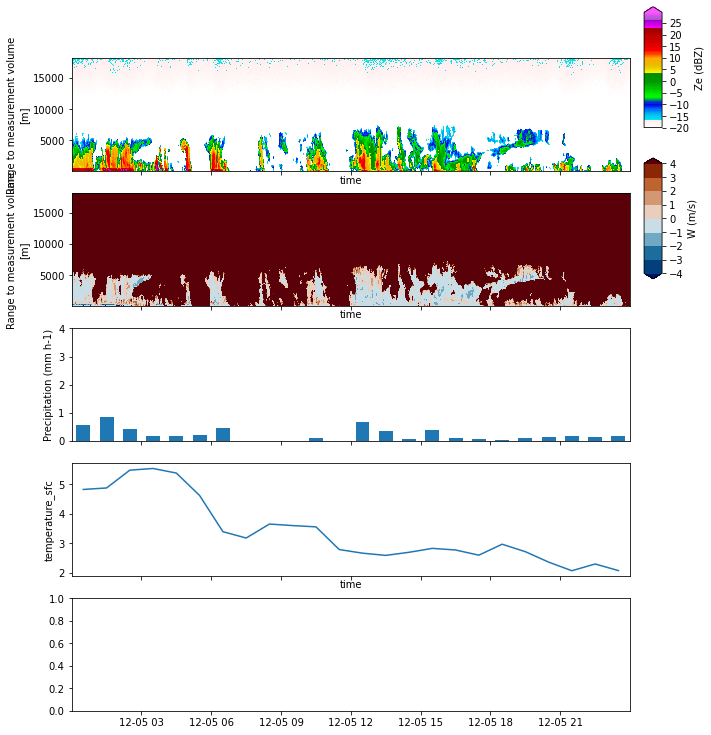

In [19]:
### Make figure
fig, axsm = plt.subplots(5, 1, figsize=[10,12], sharex=True, )
axs = axsm.flatten()

p1 = _Ze.plot.contourf(ax = axs[0], x='time', y='range', vmin = -20, 
                            levels = np.arange(-20, 30,0.5), 
                            cmap=plt.get_cmap('pymeteo_radar'), extend='max', add_colorbar=False,)
cbaxes = fig.add_axes([0.92, 0.8, 0.025, 0.14])
cbar = plt.colorbar(p1, cax=cbaxes, shrink=0.5, orientation='vertical')
cbar.ax.set_ylabel('Ze ({})'.format(_Ze.attrs['units']))

_air_temp_h.plot.contourf(x='time', levels = np.arange(-65,20,2.5),  cmap=cm.devon_r)


        
p2 = _W.plot.contourf(ax = axs[1], x='time', y='range',vmin=-4, vmax=4, 
                         levels=np.arange(-4,4.5), extend='both', cmap=cm.vik, add_colorbar=False,)
cbaxes = fig.add_axes([0.92, 0.625, 0.025, 0.14])
cbar = plt.colorbar(p2, cax=cbaxes, shrink=0.5, orientation='vertical')
cbar.ax.set_ylabel('W ({})'.format(_W.attrs['units']))

axs[2].bar(_pp['time'].values, _pp.values, width=0.025, align='center')
axs[2].set_ylabel('Precipitation (mm h-1)')
axs[2].set_ylim([0, 4])

_air_temp.plot(ax = axs[3], x='time')
axs[3].set_ylabel('2-m temperature ({})'.format(_air_temp.attrs['units']))
axs[3].hlines(y= 2., xmin=day_start, xmax=_xmax, color = 'grey')
axs[3].set_ylim([-11.5, 12.5])
        # axs[3].grid(axis='both')

# Define the date format
date_form = DateFormatter("%H:00")
for ax, tt in zip(axs,title):
            ax.set( xlabel = "Time [UTC]",
                    # title =tt
                    )
            ax.xaxis.grid()
            ax.set_xlim([day_start, _xmax])
            ax.tick_params(axis='x', labelrotation=0, )
            plt.setp(ax.get_xticklabels(), horizontalalignment="center")
            ax.xaxis.set_major_formatter(date_form)